# Задание 4.8
## Две случайные точки на отрезке: вторая — на $[a,x]$

### Условие:
На отрезке $[a,b]$ наудачу выбирается первая точка $x$, затем на отрезке $[a,x]$ наудачу выбирается вторая точка $y$. Найдите вероятности событий: $A$ — вторая точка ближе к $b$, чем первая к $a$; $B$ — расстояние между точками $x$ и $y$ меньше половины длины отрезка; $C$ — первая точка ближе ко второй, чем к точке $b$. Постройте график $\hat p(A)$ для $N=150\,000$ и приведите оценку.

### Модель:
Масштабированием и сдвигом $u=\dfrac{x-a}{b-a}$, $v=\dfrac{y-a}{b-a}$ задача сводится к отрезку $[0,1]$ (все сравнения расстояний и долей длины сохраняются), поэтому вероятности **не зависят от $a$ и $b$**. Считаем $[a,b]=[0,1]$.

**Важно:** пара $(x,y)$ **не** равномерна в треугольнике $0<y<x<1$. Сначала $x\sim U[0,1]$, затем при заданном $x$ точка $y\sim U[0,x]$, т. е. плотность $f(y|x)=\dfrac1x$ на $[0,x]$. Совместная плотность $f(x,y)=\dfrac1x$ при $0<y<x<1$ ($\iint f=\int_0^1\!\int_0^x\frac{dy}{x}dx=1$ ✓). Поэтому
$$\mathbb P(\text{событие})=\int_0^1\mathbb P(\text{событие}\mid x)\,dx,$$
а условные вероятности находим как долю длины отрезка $[0,x]$ для $y$.

### Решение:
**A:** вторая точка ближе к $b=1$, чем первая к $a=0$: $1-y<x-0$, т. е. $y>1-x$. При $y\le x$ нужна непустота $1-x<x\Leftrightarrow x>\frac12$. Тогда $\mathbb P(A|x)=\dfrac{x-(1-x)}{x}=\dfrac{2x-1}{x}$ при $x>\frac12$ и $0$ при $x\le\frac12$:
$$\mathbb P(A)=\int_{1/2}^1\frac{2x-1}{x}dx=\int_{1/2}^1\Bigl(2-\frac1x\Bigr)dx=1-\ln2\approx0{,}3069 .$$
**B:** $|x-y|<\frac12$, т. е. $y>x-\frac12$. Если $x\le\frac12$, то условие выполнено всегда ($\mathbb P(B|x)=1$); если $x>\frac12$, то $y\in(x-\frac12,x]$, длина $\frac12$: $\mathbb P(B|x)=\dfrac{1}{2x}$:
$$\mathbb P(B)=\int_0^{1/2}dx+\int_{1/2}^1\frac{dx}{2x}=\frac12+\frac{\ln2}{2}\approx0{,}8466 .$$
**C:** первая точка ближе ко второй, чем к $b$: $|x-y|<|x-1|$. Так как $y\le x<1$: $x-y<1-x\Leftrightarrow y>2x-1$. При $x\le\frac12$ это верно всегда; при $x>\frac12$ длина промежутка $(2x-1,x]$ равна $1-x$, $\mathbb P(C|x)=\dfrac{1-x}{x}$:
$$\mathbb P(C)=\frac12+\int_{1/2}^1\Bigl(\frac1x-1\Bigr)dx=\frac12+\Bigl(\ln2-\frac12\Bigr)=\ln2\approx0{,}6931 .$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

### Проверка интегралов (`sympy`)

In [2]:
import sympy as sp
x = sp.symbols('x', positive=True)
PA = sp.integrate((2*x - 1)/x, (x, sp.Rational(1, 2), 1))
PB = sp.integrate(sp.Integer(1), (x, 0, sp.Rational(1, 2))) + sp.integrate(1/(2*x), (x, sp.Rational(1, 2), 1))
PC = sp.integrate(sp.Integer(1), (x, 0, sp.Rational(1, 2))) + sp.integrate((1 - x)/x, (x, sp.Rational(1, 2), 1))
for n, v in [('A', PA), ('B', PB), ('C', PC)]: print(f'P({n}) = {sp.simplify(v)} ≈ {float(v):.7f}')
P_A, P_B, P_C = float(PA), float(PB), float(PC)

P(A) = 1 - log(2) ≈ 0.3068528
P(B) = log(2)/2 + 1/2 ≈ 0.8465736
P(C) = log(2) ≈ 0.6931472


### Моделирование для отрезка $[a,b]=[2,5]$ (показываем, что результат от $a,b$ не зависит)

In [3]:
a_, b_ = 2.0, 5.0
N = 150_000
xs = a_ + (b_ - a_)*rng.random(N)                  # первая точка: равномерно на [a, b]
ys = a_ + (xs - a_)*rng.random(N)                  # вторая точка: равномерно на [a, x]
L = b_ - a_
ev = {'A: y ближе к b, чем x к a': (b_ - ys) < (xs - a_),
      'B: |x − y| < L/2':          np.abs(xs - ys) < L/2,
      'C: x ближе к y, чем к b':   np.abs(xs - ys) < (b_ - xs)}
ex = {'A': P_A, 'B': P_B, 'C': P_C}
for name, h in ev.items(): print(f'{name:28s} точное = {ex[name[0]]:.6f}   оценка p̂ = {h.mean():.6f}  (N(A) = {h.sum()})')
print(); table(ev['A: y ближе к b, чем x к a'], P_A, Ns=(100, 1000, 10_000, 100_000, 150_000))

A: y ближе к b, чем x к a    точное = 0.306853   оценка p̂ = 0.306580  (N(A) = 45987)
B: |x − y| < L/2             точное = 0.846574   оценка p̂ = 0.847253  (N(A) = 127088)
C: x ближе к y, чем к b      точное = 0.693147   оценка p̂ = 0.695947  (N(A) = 104392)

       N        p̂(N)        |p̂ − P|      3σ_N
      100   0.2400000   6.69e-02   1.38e-01
     1000   0.3240000   1.71e-02   4.38e-02
    10000   0.3083000   1.45e-03   1.38e-02
   100000   0.3046700   2.18e-03   4.38e-03
   150000   0.3065800   2.73e-04   3.57e-03


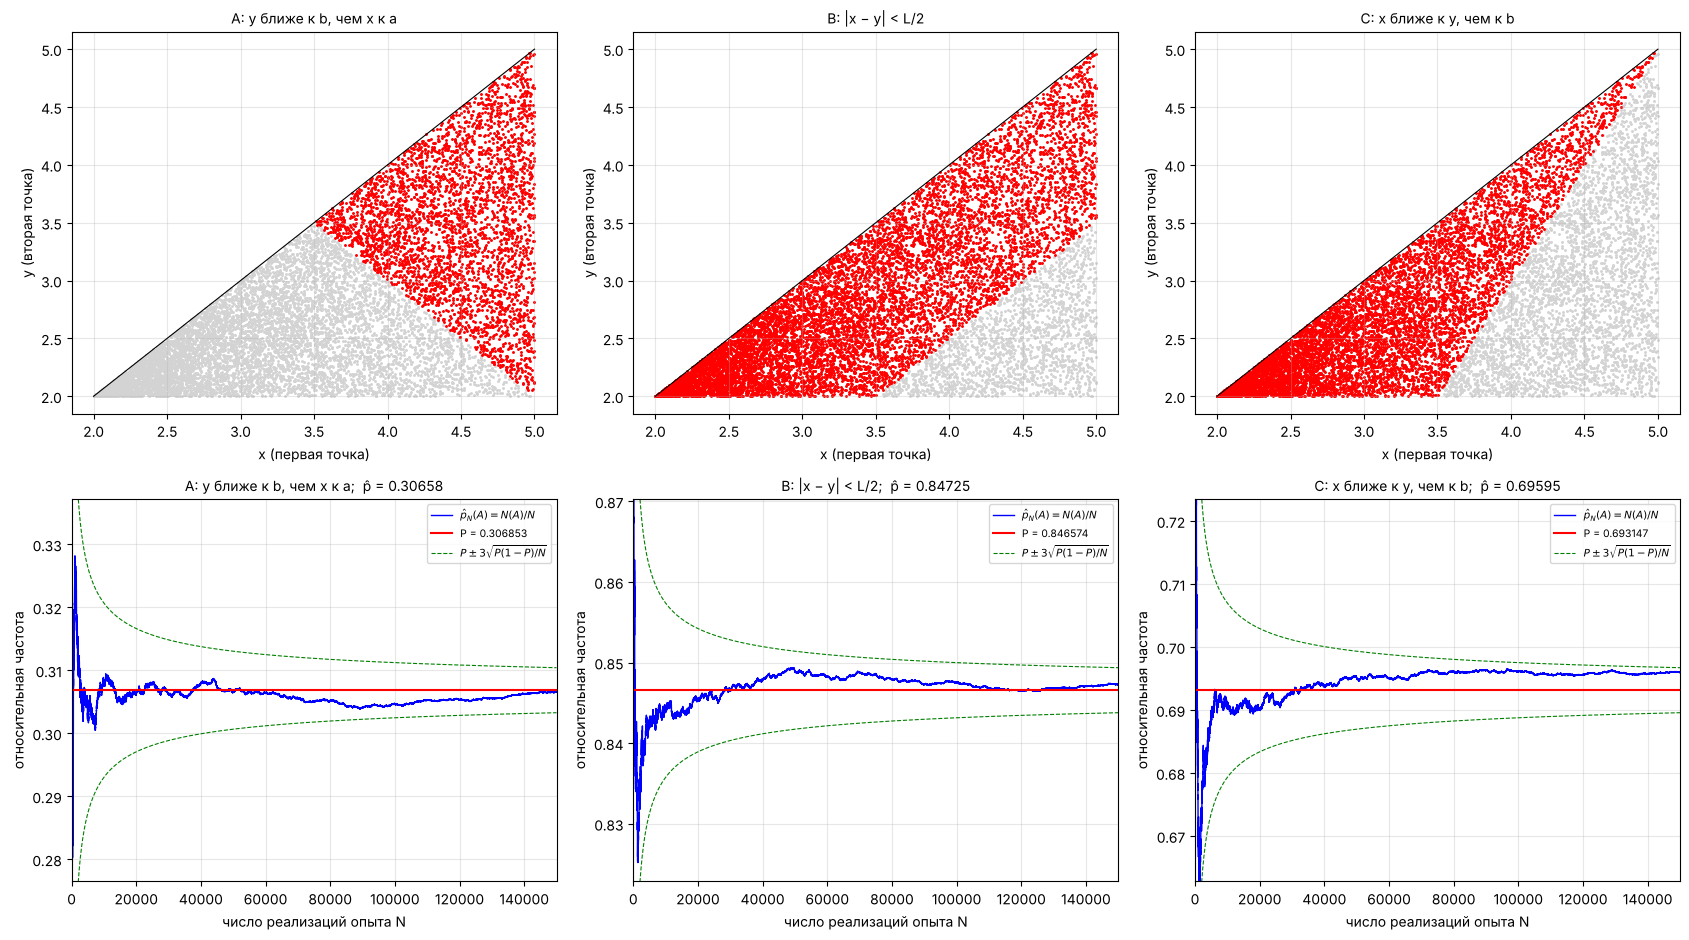

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(17, 9.5))
m = 12_000
for ax, (name, h) in zip(axs[0], ev.items()):
    ax.scatter(xs[:m][~h[:m]], ys[:m][~h[:m]], s=1.2, c='lightgray'); ax.scatter(xs[:m][h[:m]], ys[:m][h[:m]], s=1.2, c='red')
    ax.plot([a_, b_], [a_, b_], 'k-', lw=0.8); ax.set_xlabel('x (первая точка)'); ax.set_ylabel('y (вторая точка)'); ax.set_title(name, fontsize=10); ax.grid(alpha=0.3)
for ax, (name, h) in zip(axs[1], ev.items()):
    plot_frequency(ax, h, ex[name[0]], name + f';  p̂ = {h.mean():.5f}')
plt.tight_layout(); plt.savefig('task_4_8.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
$\mathbb P(A)=1-\ln2\approx0{,}3069$, $\quad\mathbb P(B)=\dfrac{1+\ln2}{2}\approx0{,}8466$, $\quad\mathbb P(C)=\ln2\approx0{,}6931$ (не зависят от $a,b$). Для $N=150\,000$ оценка $\hat p(A)$ приведена в таблице выше.